# Pruebas de YahooFinanceAPI y PriceSeries

Notebook para probar **precios, indicadores técnicos, fundamentales y análisis** con `AAPL`. Ejecuta las celdas en orden (`Shift + Enter`). No contiene datos inventados: los resultados se descargan al ejecutarlo.

## 0. Preparación

Guarda este notebook en la **misma carpeta** que `YahooFinanceAPI.py`, `priceseries.py` y el resto de clases. Este notebook asume que usas las importaciones directas (`from stock import Stock`, etc.). Si tus archivos usan `from .stock import Stock`, ábrelos como paquete desde la carpeta superior y adapta el import.

Instala las dependencias en el intérprete seleccionado por VS Code: `python3 -m pip install yfinance pandas numpy matplotlib ipykernel`. Selecciona el kernel de Python en la esquina superior derecha.

In [1]:
# Configuración de rutas para ejecutar desde tests/ o desde la raíz del proyecto
import sys
from pathlib import Path

def find_project_root(start: Path) -> Path:
    for folder in (start, *start.parents):
        if (folder / "src" / "financial_toolkit").is_dir():
            return folder
    raise FileNotFoundError("No se encontró src/financial_toolkit. Abre Financial-Toolkit como carpeta de trabajo.")

project_root = find_project_root(Path.cwd().resolve())
models_path = project_root / "src" / "financial_toolkit"
if str(models_path.parent) not in sys.path:
    sys.path.insert(0, str(models_path.parent))

# Cargar variables de entorno, si existe .env (Yahoo Finance no requiere API key)
try:
    from dotenv import load_dotenv
except ImportError:
    print("python-dotenv no instalado; se omite la carga de .env")
else:
    load_dotenv(project_root / ".env")

print(f"Raíz del proyecto: {project_root}")
print(f"Ruta de modelos: {models_path}")


Raíz del proyecto: /Users/hugoballesteromartin/Documents/HBM PRODUCTIONS/BME/Entregas/Entrega Bloque 1/Financial-Toolkit
Ruta de modelos: /Users/hugoballesteromartin/Documents/HBM PRODUCTIONS/BME/Entregas/Entrega Bloque 1/Financial-Toolkit/src/models


In [2]:
from dataclasses import asdict
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from financial_toolkit.YahooFinanceAPI import YahooFinanceAPI
from financial_toolkit.priceseries import PriceSeries

print("Importaciones correctas")

Importaciones correctas


## 1. Descargar una acción

In [3]:
api = YahooFinanceAPI()
stock = api.get_stock("AAPL", period="5y", interval="1d")

print("Ticker:", stock.ticker)
print("Empresa:", stock.company.name)
print("País:", stock.company.country)
print("Industria:", stock.company.industry)

Ticker: AAPL
Empresa: Apple Inc.
País: United States
Industria: Consumer Electronics


## 2. Comprobar la estructura de PriceSeries

La API debe construir `PriceSeries(date=..., open=..., high=..., low=..., close=..., volume=...)` y `Stock.price` debe ser de tipo `PriceSeries`.

In [4]:
assert isinstance(stock.price, PriceSeries), "Stock.price no es PriceSeries: revisa YahooFinanceAPI y stock.py"
assert len(stock.price.close) > 0
assert len(stock.price.date) == len(stock.price.close)
assert len(stock.price.open) == len(stock.price.close)
assert len(stock.price.high) == len(stock.price.close)
assert len(stock.price.low) == len(stock.price.close)
assert len(stock.price.volume) == len(stock.price.close)
print("PriceSeries: OK")

PriceSeries: OK


## 3. Ver los precios en una tabla

In [5]:
prices_df = pd.DataFrame({
    "Open": stock.price.open,
    "High": stock.price.high,
    "Low": stock.price.low,
    "Close": stock.price.close,
    "Volume": stock.price.volume,
})
display(prices_df.tail(10))

,Open,High,Low,Close,Volume
Date,,,,,
2026-10-21 00:00:00-04:00,339.359985,345.250000,338.829987,343.989990,35614100
2026-10-22 00:00:00-04:00,344.940002,348.359985,342.279999,348.220001,46898900
2026-10-23 00:00:00-04:00,349.119995,351.730011,345.750000,347.730011,39539700
2026-10-26 00:00:00-04:00,343.920013,347.089996,341.029999,343.910004,42743600
2026-10-27 00:00:00-04:00,343.170013,347.779999,342.390015,347.100006,39984400
2026-10-28 00:00:00-04:00,346.920013,347.179993,343.519989,343.829987,35714300
2026-10-29 00:00:00-04:00,348.000000,351.429993,347.299988,348.910004,42582100
2026-10-30 00:00:00-04:00,346.720001,349.190002,334.350006,344.630005,67841600
2026-11-02 00:00:00-05:00,342.670013,343.799988,335.820007,338.320007,63842300


## 4. Métodos básicos y rentabilidades

In [6]:
print(f"Último cierre: {stock.price.current_price():,.2f}")
print(f"Máximo: {stock.price.max_price():,.2f}")
print(f"Mínimo: {stock.price.min_price():,.2f}")
print(f"Rentabilidad acumulada: {stock.price.cumulative_return():.2%}")
print(f"Rentabilidad media por intervalo: {stock.price.compute_mean_return():.4%}")
print(f"Volatilidad por intervalo: {stock.price.compute_volatility():.4%}")
print(f"Máximo drawdown: {stock.price.max_drawdown():.2%}")

display(stock.price.compute_return().tail(10).rename("Log return").to_frame())

Último cierre: 331.76
Máximo: 348.91
Mínimo: 122.83
Rentabilidad acumulada: 124.52%
Rentabilidad media por intervalo: 0.0645%
Volatilidad por intervalo: 1.7612%
Máximo drawdown: -33.36%


,Log return
Date,
2026-10-21 00:00:00-04:00,0.013139
2026-10-22 00:00:00-04:00,0.012222
2026-10-23 00:00:00-04:00,-0.001408
2026-10-26 00:00:00-04:00,-0.011046
2026-10-27 00:00:00-04:00,0.009233
2026-10-28 00:00:00-04:00,-0.009466
2026-10-29 00:00:00-04:00,0.014667
2026-10-30 00:00:00-04:00,-0.012343
2026-11-02 00:00:00-05:00,-0.018479


## 5. SMA, EMA y MACD

In [7]:
indicators = pd.DataFrame({
    "Close": stock.price.close,
    "SMA 50": stock.price.sma(50),
    "SMA 200": stock.price.sma(200),
    "EMA 20": stock.price.ema(20),
})
display(indicators.tail(10).round(2))
display(stock.price.macd().tail(10).round(3))

,Close,SMA 50,SMA 200,EMA 20
Date,,,,
2026-10-21 00:00:00-04:00,343.99,327.70,293.23,338.21
2026-10-22 00:00:00-04:00,348.22,328.62,293.67,339.16
2026-10-23 00:00:00-04:00,347.73,329.47,294.11,339.98
2026-10-26 00:00:00-04:00,343.91,330.23,294.54,340.35
2026-10-27 00:00:00-04:00,347.10,331.06,294.98,340.99
2026-10-28 00:00:00-04:00,343.83,331.73,295.40,341.26
2026-10-29 00:00:00-04:00,348.91,332.37,295.84,341.99
2026-10-30 00:00:00-04:00,344.63,333.04,296.27,342.24
2026-11-02 00:00:00-05:00,338.32,333.62,296.67,341.87


,MACD,Signal,Histogram
Date,,,
2026-10-21 00:00:00-04:00,3.858,3.928,-0.070
2026-10-22 00:00:00-04:00,4.196,3.982,0.215
2026-10-23 00:00:00-04:00,4.375,4.060,0.314
2026-10-26 00:00:00-04:00,4.160,4.080,0.079
2026-10-27 00:00:00-04:00,4.198,4.104,0.094
2026-10-28 00:00:00-04:00,3.920,4.067,-0.147
2026-10-29 00:00:00-04:00,4.062,4.066,-0.004
2026-10-30 00:00:00-04:00,3.786,4.010,-0.224
2026-11-02 00:00:00-05:00,3.023,3.813,-0.789


## 6. RSI y bandas de Bollinger

In [8]:
display(stock.price.rsi().tail(10).rename("RSI 14").to_frame().round(2))
display(stock.price.bollinger_bands().tail(10).round(2))

,RSI 14
Date,
2026-10-21 00:00:00-04:00,60.65
2026-10-22 00:00:00-04:00,64.76
2026-10-23 00:00:00-04:00,63.93
2026-10-26 00:00:00-04:00,57.70
2026-10-27 00:00:00-04:00,61.11
2026-10-28 00:00:00-04:00,56.12
2026-10-29 00:00:00-04:00,61.39
2026-10-30 00:00:00-04:00,55.35
2026-11-02 00:00:00-05:00,47.88


,Upper,Middle,Lower
Date,,,
2026-10-21 00:00:00-04:00,347.10,337.96,328.81
2026-10-22 00:00:00-04:00,348.74,338.57,328.41
2026-10-23 00:00:00-04:00,349.83,338.91,327.99
2026-10-26 00:00:00-04:00,350.32,339.18,328.04
2026-10-27 00:00:00-04:00,350.74,340.07,329.39
2026-10-28 00:00:00-04:00,350.86,340.61,330.35
2026-10-29 00:00:00-04:00,351.22,341.54,331.85
2026-10-30 00:00:00-04:00,351.12,342.08,333.05
2026-11-02 00:00:00-05:00,350.51,342.36,334.20


## 7. Dibujar el precio y las medias móviles

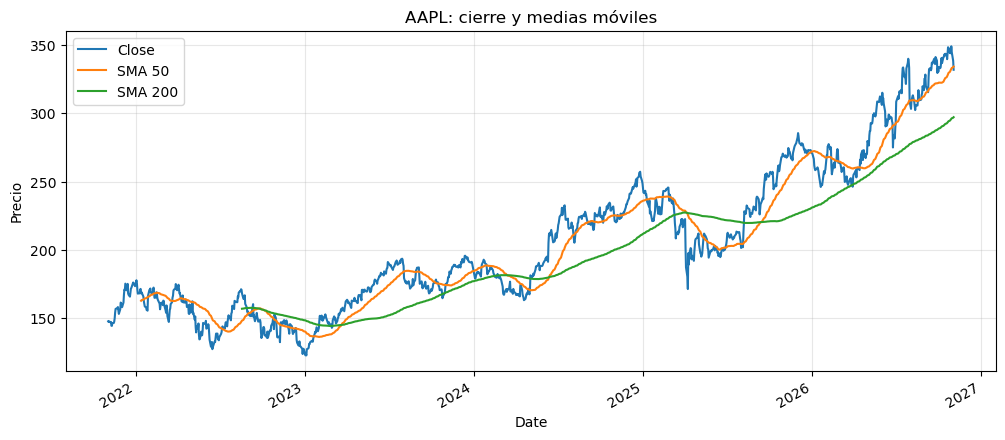

In [9]:
ax = indicators[["Close", "SMA 50", "SMA 200"]].plot(figsize=(12, 5), title=f"{stock.ticker}: cierre y medias móviles")
ax.set_ylabel("Precio")
ax.grid(alpha=0.3)
plt.show()

## 8. Dibujar MACD y drawdown

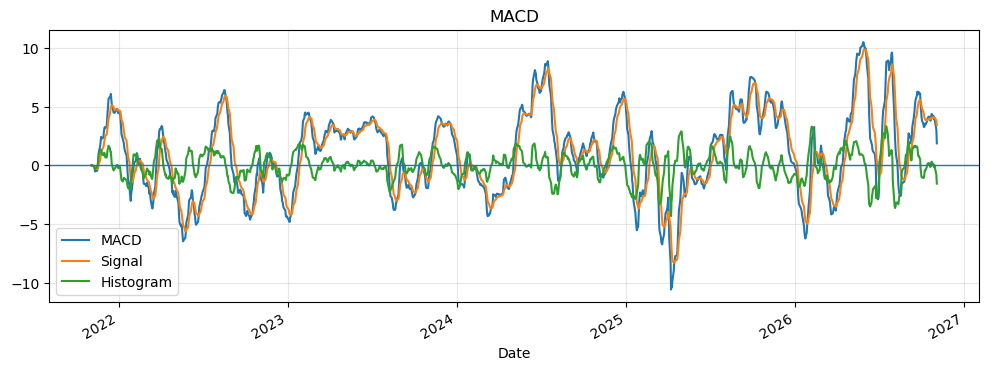

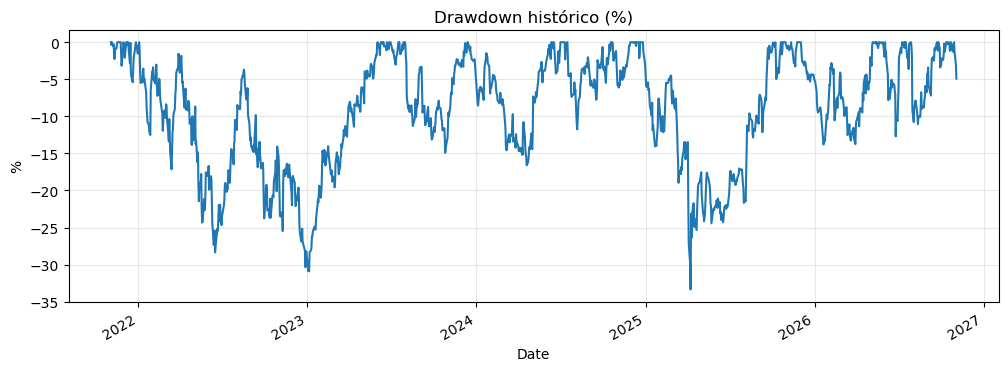

In [10]:
ax = stock.price.macd()[["MACD", "Signal", "Histogram"]].plot(figsize=(12, 4), title="MACD")
ax.axhline(0, linewidth=1)
ax.grid(alpha=0.3)
plt.show()

ax = (stock.price.compute_drawdown() * 100).plot(figsize=(12, 4), title="Drawdown histórico (%)")
ax.set_ylabel("%")
ax.grid(alpha=0.3)
plt.show()

## 9. Comprobar los historiales financieros

In [11]:
fundamentals = stock.company.fundamentals
income_history = fundamentals.income_statements
balance_history = fundamentals.balance_sheets
cashflow_history = fundamentals.cash_flows

print("Ejercicios de resultados:", len(income_history.statements))
print("Ejercicios de balance:", len(balance_history.statements))
print("Ejercicios de flujo de caja:", len(cashflow_history.statements))

Ejercicios de resultados: 4
Ejercicios de balance: 4
Ejercicios de flujo de caja: 4


## 10. Estados financieros en tablas (millones)

Cada fila es una partida y cada columna un ejercicio. Los valores ausentes de Yahoo Finance se muestran como `NaN`.

In [12]:
income_df = pd.DataFrame([asdict(s) for s in income_history.statements])
if not income_df.empty:
    display((income_df.set_index("date").T / 1_000_000).round(2))
else:
    print("No hay cuenta de resultados disponible")

date,2025-09-30,2024-09-30,2023-09-30,2022-09-30
total_revenue,416161.0,391035.0,383285.0,394328.0
cost_revenue,220960.0,210352.0,214137.0,223546.0
gross_profit,195201.0,180683.0,169148.0,170782.0
operating_expense,62151.0,57467.0,54847.0,51345.0
operating_income,133050.0,123216.0,114301.0,119437.0
interest_expense,NaN,NaN,3933.0,2931.0
pretax_income,132729.0,123485.0,113736.0,119103.0
tax_provision,20719.0,29749.0,16741.0,19300.0
net_income,112010.0,93736.0,96995.0,99803.0


In [13]:
balance_df = pd.DataFrame([asdict(s) for s in balance_history.statements])
if not balance_df.empty:
    display((balance_df.set_index("date").T / 1_000_000).round(2))
else:
    print("No hay balance disponible")

date,2025-09-30,2024-09-30,2023-09-30,2022-09-30
cash_equivalents,54697.0,65171.0,61555.0,48304.0
total_debt,98657.0,106629.0,111088.0,132480.0
account_receivable,39777.0,33410.0,29508.0,28184.0
inventory,5718.0,7286.0,6331.0,4946.0
current_assets,147957.0,152987.0,143566.0,135405.0
net_ppe,49834.0,45680.0,43715.0,42117.0
goodwill_intangible,NaN,NaN,NaN,NaN
total_assets,359241.0,364980.0,352583.0,352755.0
current_liabilities,165631.0,176392.0,145308.0,153982.0
long_term_debt,78328.0,85750.0,95281.0,98959.0


In [14]:
cashflow_df = pd.DataFrame([asdict(s) for s in cashflow_history.statements])
if not cashflow_df.empty:
    display((cashflow_df.set_index("date").T / 1_000_000).round(2))
else:
    print("No hay flujo de caja disponible")

date,2025-09-30,2024-09-30,2023-09-30,2022-09-30
net_income_continuing_operations,112010.0,93736.0,96995.0,99803.0
depreciation_amortization,11698.0,11445.0,11519.0,11104.0
change_working_capital,-25000.0,3651.0,-6577.0,1200.0
operating_cash_flow,111482.0,118254.0,110543.0,122151.0
capital_expenditure,-12715.0,-9447.0,-10959.0,-10708.0
investing_cash,15195.0,2935.0,3705.0,-22354.0
issuance_debt,4481.0,0.0,5228.0,5465.0
repayment_debt,-10932.0,-9958.0,-11151.0,-9543.0
repurchase_stock,-90711.0,-94949.0,-77550.0,-89402.0
cash_dividends_paid,-15421.0,-15234.0,-15025.0,-14841.0


## 11. Pruebas automáticas de consistencia

Estas comprobaciones no requieren conocer los precios de antemano.

In [15]:
assert stock.ticker == "AAPL"
assert (stock.price.close.dropna() > 0).all(), "Hay precios de cierre no positivos"
assert np.isclose(stock.price.current_price(), stock.price.close.iloc[-1])
assert np.isclose(stock.price.cumulative_return(), stock.price.close.iloc[-1] / stock.price.close.iloc[0] - 1, atol=1e-8)
assert stock.price.max_drawdown() <= 0
assert stock.price.max_drawdown() >= -1
assert len(stock.price.sma(50)) == len(stock.price.close)
assert len(stock.price.macd()) == len(stock.price.close)
print("Todas las pruebas básicas han pasado")

Todas las pruebas básicas han pasado


## Notas

- La descarga necesita conexión a internet y puede depender de la disponibilidad de Yahoo Finance.
- Los cálculos se realizan sobre `Close` ajustado porque tu API usa `auto_adjust=True`.
- La media y la volatilidad corresponden al intervalo descargado; con `interval="1d"` son diarias.
- Si el código de tu proyecto todavía devuelve un `pd.DataFrame` en `Stock.price`, actualiza la API para construir `PriceSeries` antes de ejecutar este notebook.
- Para evitar fallos por falta de datos, las celdas de fundamentales comprueban si cada historial está vacío.